# 01 — Calidad de datos y verificaciones exploratorias

**Objetivo.** Antes de modelar, averiguar qué tiene de raro el archivo crudo y decidir qué hacer con
cada rareza. Cada decisión que se toma aquí queda registrada en `docs/DECISIONS.md` (ADR-008 y
ADR-009).

**Qué cubre este notebook**

1. Tasa del target y valores faltantes
2. Códigos de categoría que no están en la documentación del dataset
3. Códigos de estado de pago (`PAY_*`): cuáles hay, qué parecen significar y por qué el estado de
   septiembre exige cuidado
4. Saldos negativos, saldos por encima del límite de crédito y cuentas inactivas
5. Filas idénticas
6. Valores extremos
7. Qué estado de cuenta cancela cada pago (timing de pagos)
8. La recodificación fija que se aplica a los datos
9. Qué columnas están disponibles al momento de predecir

**Qué deja fuera a propósito.** Todavía no existe la partición train/test, así que mirar aquí tasas
de default por variable sería mirar filas que después formarán el conjunto de test. El target se usa
solo en dos lugares: la tasa global de default y el conteo de filas idénticas. El análisis de cada
variable frente al target se hace en el notebook de binning, solo con datos de entrenamiento.

Todas las verificaciones son funciones de `creditrisk.data.quality`; este notebook las llama y
explica los resultados. Las cifras se guardan al final en `reports/metrics/data_quality.json`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from creditrisk import plotting
from creditrisk.data import clean, quality
from creditrisk.data.load import load_project_data
from creditrisk.data.schema import (
    BILL_COLS,
    CANDIDATE_FEATURE_COLS,
    DOCUMENTED_CODES,
    MONTH_LABELS,
    PAY_COLS,
    PAYAMT_COLS,
    SENSITIVE_COLS,
    TARGET,
)
from creditrisk.reporting import save_metrics

plotting.apply_style()
pd.set_option("display.max_columns", 30)

# Spanish headers for the tables shown in this notebook (the library keeps English names).
HEADERS = {
    "value": "valor",
    "code": "código",
    "month": "mes",
    "calendar_month": "mes calendario",
    "count": "cuentas",
    "share": "proporción",
    "documented": "documentado",
    "n": "cuentas-mes",
    "share_statement_not_positive": "sin saldo que pagar",
    "share_no_payment": "sin pago",
    "share_paid_in_full": "pagó completo (si había saldo)",
    "n_bill_not_positive": "factura cero o negativa",
    "n_with_delay_code": "de ellas, con código de atraso",
    "n_with_code_minus_2": "de ellas, con código -2",
    "n_negative_bill": "facturas negativas",
    "min_bill": "factura mínima",
    "n_bill_over_limit": "facturas sobre el límite",
    "n_negative_payment": "pagos negativos",
    "n_paying": "cuentas que pagaron",
    "share_equals_previous_bill": "pago = factura del mes anterior",
    "share_equals_same_month_bill": "pago = factura del mismo mes",
    "share_equals_both": "pago = ambas facturas",
    "share_negative_if_settles_previous_bill": "compras negativas si cancela la factura anterior",
    "share_negative_if_settles_same_month_bill": "compras negativas si cancela la del mismo mes",
}


def show(table, percent=(), whole=()):
    """Display a table with shares as percentages, counts with separators and Spanish headers."""
    out = table.copy()
    for column in percent:
        out[column] = out[column].map("{:.1%}".format, na_action="ignore")
    for column in whole:
        out[column] = out[column].map("{:,.0f}".format)
    out.index.name = HEADERS.get(out.index.name, out.index.name)
    display(out.rename(columns=HEADERS))

## Carga del archivo crudo

`load_project_data` compara el SHA-256 del archivo con el de `config/project.yaml` y valida el
esquema, así que todo lo que sigue corre sobre el archivo exacto descrito en `docs/DATA.md`.

Convención de columnas: mes 1 = septiembre de 2005 (el más reciente) … mes 6 = abril de 2005. El
target es el default en octubre de 2005. El archivo crudo trae además una columna `ID`, un número de
fila de 1 a 30,000 que el cargador descarta; no está documentada como clave de cliente.

In [2]:
raw, data_sha256 = load_project_data()
print(f"SHA-256: {data_sha256}")
print(f"Tamaño:  {raw.shape[0]:,} filas x {raw.shape[1]} columnas")
raw.head()

SHA-256: 30c6be3abd8dcfd3e6096c828bad8c2f011238620f5369220bd60cfc82700933
Tamaño:  30,000 filas x 24 columnas


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


## 1. Tasa del target y valores faltantes

El cargador falla si el archivo no tiene 30,000 filas y 6,636 defaults, que son los conteos del
archivo sobre el que se construye este proyecto. Se muestran aquí para que consten.

In [3]:
target = quality.target_summary(raw)
missing = quality.missing_counts(raw)

print(f"Filas:             {target['n_rows']:,}")
print(f"Defaults:          {target['n_defaults']:,}")
print(f"Tasa de default:   {target['default_rate']:.2%}")
print(f"Valores faltantes: {sum(missing.values())} (todas las columnas juntas)")

Filas:             30,000
Defaults:          6,636
Tasa de default:   22.12%
Valores faltantes: 0 (todas las columnas juntas)


No hay valores faltantes guardados como nulos. Eso no significa que los datos estén completos: como
muestran las secciones siguientes, lo "desconocido" está escondido dentro de códigos de categoría no
documentados.

El archivo no dice cómo se definió "default" ni cómo se muestrearon los clientes, así que la tasa de
default se toma como dato y no se lee como la tasa de default de toda la cartera del banco.

## 2. Códigos de categoría fuera de la documentación

La documentación lista `SEX` 1–2, `EDUCATION` 1–4 (4 = otros) y `MARRIAGE` 1–3 (3 = otros).

In [4]:
for column in ["SEX", "EDUCATION", "MARRIAGE"]:
    table = quality.code_counts(raw, column, DOCUMENTED_CODES[column])
    undocumented = table.loc[~table["documented"], "count"].sum()
    print(
        f"{column}: {undocumented:,} filas con un código no documentado "
        f"({undocumented / len(raw):.2%} del archivo)"
    )
    show(table.set_index("value"), percent=["share"], whole=["count"])

SEX: 0 filas con un código no documentado (0.00% del archivo)


,cuentas,proporción,documentado
valor,,,
1,"11,888",39.6%,True
2,"18,112",60.4%,True


EDUCATION: 345 filas con un código no documentado (1.15% del archivo)


,cuentas,proporción,documentado
valor,,,
0,14,0.0%,False
1,"10,585",35.3%,True
2,"14,030",46.8%,True
3,"4,917",16.4%,True
4,123,0.4%,True
5,280,0.9%,False
6,51,0.2%,False


MARRIAGE: 54 filas con un código no documentado (0.18% del archivo)


,cuentas,proporción,documentado
valor,,,
0,54,0.2%,False
1,"13,659",45.5%,True
2,"15,964",53.2%,True
3,323,1.1%,True


`EDUCATION` tiene tres códigos no documentados (0, 5, 6) y `MARRIAGE` tiene uno (0). `SEX` está
limpio.

**Decisión (ADR-008).** Los códigos no documentados pasan a la categoría documentada "otros"
(`EDUCATION` → 4, `MARRIAGE` → 3). Nada en la documentación distingue estos códigos, son una parte
pequeña del archivo, y "otros" es la única categoría documentada que no afirma saber qué significan.
La decisión se toma sin mirar sus tasas de default.

## 3. Códigos de estado de pago

La documentación describe `PAY_*` como −1 = pagó puntualmente y 1–9 = meses de atraso en el pago. La
tabla cuenta las cuentas por código y por mes.

In [5]:
pay_counts = quality.pay_code_counts(raw)
show(pay_counts, whole=PAY_COLS)
print(
    "Proporción de cuentas-mes con un código no documentado: "
    f"{quality.undocumented_pay_share(raw):.1%}"
)

,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,documentado
código,,,,,,,
-2,"2,759","3,782","4,085","4,348","4,546","4,895",False
-1,"5,686","6,050","5,938","5,687","5,539","5,740",True
0,"14,737","15,730","15,764","16,455","16,947","16,286",False
1,"3,688",28,4,2,0,0,True
2,"2,667","3,927","3,819","3,159","2,626","2,766",True
3,322,326,240,180,178,184,True
4,76,99,76,69,84,49,True
5,26,25,21,35,17,13,True
6,11,12,23,5,4,19,True


Proporción de cuentas-mes con un código no documentado: 66.9%


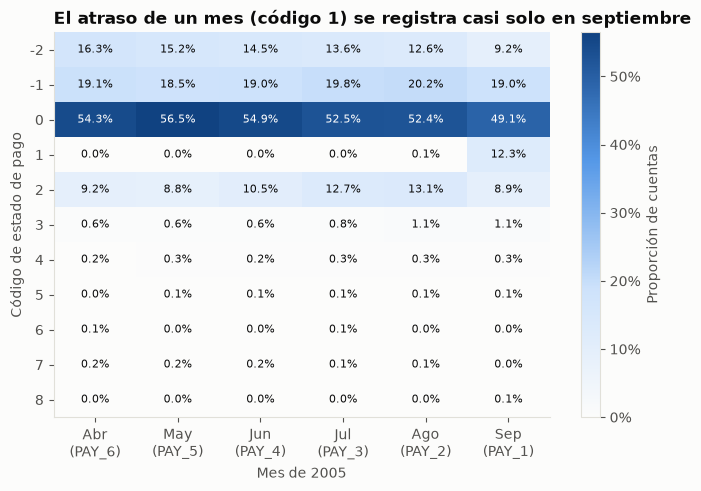

In [6]:
# Months in calendar order (April -> September) so the chart reads left to right in time.
months = sorted(MONTH_LABELS, reverse=True)
shares = pay_counts[[f"PAY_{k}" for k in months]] / len(raw)

fig, ax = plt.subplots(figsize=(8, 5))
image = ax.imshow(shares.to_numpy(), cmap=plotting.SEQUENTIAL, aspect="auto", vmin=0)
ax.set_xticks(range(len(months)), [f"{MONTH_LABELS[k]}\n(PAY_{k})" for k in months])
ax.set_yticks(range(len(shares)), shares.index)
ax.set_xlabel("Mes de 2005")
ax.set_ylabel("Código de estado de pago")
ax.grid(False)
for i in range(shares.shape[0]):
    for j in range(shares.shape[1]):
        value = shares.iat[i, j]
        colour = "white" if value > 0.3 else plotting.INK
        ax.text(j, i, f"{value:.1%}", ha="center", va="center", fontsize=8, color=colour)
fig.colorbar(image, ax=ax, label="Proporción de cuentas", format=lambda x, _: f"{x:.0%}")
ax.set_title("El atraso de un mes (código 1) se registra casi solo en septiembre")
plotting.save_figure(fig, "eda_pay_code_shares")
plt.show()

Destacan tres cosas.

- **Alrededor de dos tercios de las cuentas-mes llevan un código no documentado.** Los códigos −2 y
  0 no están en la documentación, y aun así el 0 es el valor más frecuente en todos los meses.
- **El código 1 casi no existe fuera de septiembre.** Un atraso de un mes se registra 3,688 veces en
  `PAY_1` y como máximo 28 veces en cualquier mes anterior, mientras que el atraso de dos meses es
  frecuente en todos los meses. Septiembre parece registrarse con un criterio distinto al de los
  meses anteriores. El archivo no explica por qué.
- **El código 9 nunca aparece**, aunque está documentado.

### ¿Qué significan los códigos?

Los códigos −2 y 0 suelen leerse como "sin consumo" y "crédito revolvente" (se pagó el mínimo y no
se canceló el saldo). Esa lectura no tiene documentación detrás y aquí no se cita ninguna fuente
para ella. Se puede contrastar con las facturas y los pagos, pero primero hay que saber a *qué*
factura y a *qué* pago se refiere el estado de un mes. El archivo no lo dice, así que se comparan
dos emparejamientos en los meses donde ambos se pueden calcular (mayo a agosto):

- **mes siguiente:** el estado de cuenta del mes *k* y el pago hecho el mes siguiente;
- **mismo mes:** el estado de cuenta del mes anterior y el pago hecho en el mes *k*.

Para cada código la tabla da el número de cuentas-mes, la proporción sin nada que pagar (estado de
cuenta en cero o negativo), la proporción sin pago y, entre las que sí tenían algo que pagar, la
proporción que lo pagó completo.

In [7]:
shared_months = [2, 3, 4, 5]  # August ... May: the months where both pairings exist
share_columns = ["share_statement_not_positive", "share_no_payment", "share_paid_in_full"]
pairings = {"following_month": "pago del mes siguiente", "same_month": "pago del mismo mes"}

for pairing, label in pairings.items():
    print(f"Emparejamiento: {label} (meses {shared_months})")
    show(
        quality.pay_status_profile(raw, pairing, shared_months), percent=share_columns, whole=["n"]
    )

Emparejamiento: pago del mes siguiente (meses [2, 3, 4, 5])


,cuentas-mes,sin saldo que pagar,sin pago,pagó completo (si había saldo)
código,,,,
-2,"16,761",63.4%,61.7%,93.5%
-1,"23,214",10.5%,10.1%,98.4%
0,"64,896",2.0%,3.9%,0.2%
1,34,61.8%,29.4%,0.0%
2,"13,531",2.5%,48.2%,0.3%
3,924,0.0%,76.2%,0.2%
4,328,0.0%,77.4%,0.0%
5,98,0.0%,84.7%,0.0%
6,44,0.0%,95.5%,0.0%


Emparejamiento: pago del mismo mes (meses [2, 3, 4, 5])


,cuentas-mes,sin saldo que pagar,sin pago,pagó completo (si había saldo)
código,,,,
-2,"16,761",56.4%,55.1%,95.3%
-1,"23,214",15.6%,22.2%,75.8%
0,"64,896",4.1%,8.0%,5.1%
1,34,35.3%,35.3%,40.9%
2,"13,531",3.8%,27.8%,7.2%
3,924,0.0%,60.8%,0.2%
4,328,0.0%,81.1%,0.0%
5,98,0.0%,86.7%,0.0%
6,44,0.0%,79.5%,0.0%


El emparejamiento con el **mes siguiente** encaja mucho mejor con los códigos documentados:

- Código −1 ("pagó puntualmente"): el 98.4% de los estados de cuenta positivos se pagó completo al
  mes siguiente, frente al 75.8% con el emparejamiento del mismo mes.
- Código 2 (dos meses de atraso): el 0.3% pagó completo y el 48.2% no pagó nada al mes siguiente.
- Código 0: casi nunca sin estado de cuenta (2.0%), casi nunca pagado completo (0.2%), y hay un pago
  en todas las cuentas-mes salvo el 3.9%. Encaja con "crédito revolvente".
- Código −2: el 63.4% de las cuentas-mes no tiene nada que pagar, y donde sí hay algo que pagar, el
  93.5% lo paga completo. Se parece a "sin saldo, o saldo cancelado", que es más amplio que "sin
  consumo".

Entonces, de abril a agosto, el estado de un mes parece describir cómo se pagó el estado de cuenta
de ese mes **en el mes siguiente**. Esto concuerda con el resultado de timing de pagos de la
sección 7.

### Por qué el estado de septiembre exige cuidado

Para septiembre (`PAY_1`) el pago siguiente se haría en octubre, que es el mes del resultado y no
está en el archivo. Hay dos explicaciones posibles, y el archivo no permite distinguirlas:

1. `PAY_1` se fijó usando lo que pasó en octubre. Contendría entonces información del período del
   resultado.
2. `PAY_1` se registró antes y con un criterio distinto al de los otros meses.

La anomalía del código 1 apunta a la segunda. Las dos tablas siguientes aportan más: el estado de
septiembre con el único emparejamiento disponible para ese mes, y el estado que reciben las cuentas
a las que no se les facturó nada.

In [8]:
print("Estado de septiembre frente al estado de cuenta de agosto y el pago de septiembre")
show(quality.pay_status_profile(raw, "same_month", [1]), percent=share_columns, whole=["n"])

no_bill = quality.status_without_bill(raw)
no_bill.insert(1, "calendar_month", no_bill["month"].map(MONTH_LABELS))
print("Estado de las cuentas cuya factura del mes es cero o negativa")
show(no_bill.set_index("month"), whole=["n_bill_not_positive", "n_with_delay_code"])

Estado de septiembre frente al estado de cuenta de agosto y el pago de septiembre


,cuentas-mes,sin saldo que pagar,sin pago,pagó completo (si había saldo)
código,,,,
-2,"2,759",34.5%,33.1%,92.9%
-1,"5,686",12.4%,18.0%,77.3%
0,"14,737",1.9%,1.8%,3.4%
1,"3,688",31.9%,59.4%,26.7%
2,"2,667",2.4%,20.4%,4.9%
3,322,0.0%,61.8%,0.0%
4,76,0.0%,76.3%,0.0%
5,26,0.0%,88.5%,0.0%
6,11,0.0%,100.0%,0.0%


Estado de las cuentas cuya factura del mes es cero o negativa


,mes calendario,factura cero o negativa,"de ellas, con código de atraso","de ellas, con código -2"
mes,,,,
1,Sep,"2,598","1,689",903
2,Ago,"3,175",84,2106
3,Jul,"3,525",125,2512
4,Jun,"3,870",96,2902
5,May,"4,161",52,3100
6,Abr,"4,708",22,3467


En septiembre, 1,689 cuentas sin factura positiva llevan un código de atraso. En los meses
anteriores la misma situación recibe un código de atraso en 22 a 125 cuentas y se codifica como −2.
Una parte grande del grupo "un mes de atraso" de septiembre no es, por tanto, una mora que se pueda
ver en las facturas.

**Decisiones.**

- **ADR-008.** Los valores de `PAY_*` se conservan tal como están. Los códigos −2 y 0 se tratan como
  categorías propias: no se fusionan con −1 ni se colocan en la escala de "meses de atraso". Su
  significado es un **SUPUESTO**, respaldado por la tabla de arriba solo para abril a agosto.
- **ADR-009.** `PAY_1` sigue como variable candidata, pero su disponibilidad al momento de puntuar
  es un **SUPUESTO**. Tendrá una verificación de fuga con nombre propio en las fases de binning y de
  modelado, con datos de entrenamiento: su information value frente al umbral de alarma de 0.5, y el
  desempeño del modelo con y sin ella.
- Las matrices de transición mes a mes del análisis de cobranza no pueden tratar a septiembre como a
  los otros meses. Esto se arrastra como limitación de ese análisis.

## 4. Saldos negativos, saldos sobre el límite y cuentas inactivas

El archivo no define qué es una factura negativa. Aquí se lee como saldo a favor (el cliente pagó de
más o recibió una devolución), y una factura mayor que `LIMIT_BAL` como una cuenta sobregirada.
Ambas lecturas son interpretaciones.

In [9]:
balances = quality.balance_anomalies(raw)
balances.insert(1, "calendar_month", balances["month"].map(MONTH_LABELS))
show(balances.set_index("month"), whole=["n_negative_bill", "min_bill", "n_bill_over_limit"])

inactive = quality.inactive_account_summary(raw)
labels = {
    "n_all_bills_zero": "Cuentas con todas las facturas en cero",
    "n_all_amounts_zero": "Cuentas con todas las facturas y pagos en cero",
    "n_all_amounts_zero_with_delay_in_pay_1": "  de ellas, con código de atraso en PAY_1",
}
for name, value in inactive.items():
    print(f"{labels[name]:<48}{value:>6,}")

,mes calendario,facturas negativas,factura mínima,facturas sobre el límite,pagos negativos
mes,,,,,
1,Sep,590,"-165,580","2,115",0
2,Ago,669,"-69,777","1,940",0
3,Jul,655,"-157,264","1,583",0
4,Jun,675,"-170,000","1,018",0
5,May,655,"-81,334",820,0
6,Abr,688,"-339,603",798,0


Cuentas con todas las facturas en cero             866
Cuentas con todas las facturas y pagos en cero     795
  de ellas, con código de atraso en PAY_1          495


Hay facturas negativas y facturas sobre el límite en todos los meses, y ningún monto de pago es
negativo.

795 cuentas tienen todas las facturas y todos los pagos en cero durante los seis meses: tienen una
tarjeta y no la usan. 495 de ellas llevan un código de atraso en septiembre aunque nunca se les
facturó nada, que es la misma anomalía de la sección 3.

**Decisiones (ADR-008).**

- Los montos de las facturas se conservan tal como están. Donde una fórmula necesita un saldo no
  negativo (utilización, el proxy de exposición de ADR-004), el piso en cero se aplica dentro de esa
  fórmula y se declara ahí.
- Las cuentas inactivas permanecen en la población. Tienen una línea de crédito abierta, así que un
  banco las puntuaría, y quitarlas cambiaría la población a la que se refiere todo resultado
  posterior.

## 5. Filas idénticas

Una vez descartado el número de fila `ID`, algunas filas son idénticas en todas las columnas.

In [10]:
duplicates = quality.duplicate_summary(raw)
labels = {
    "n_duplicate_rows": "Filas que repiten una fila anterior",
    "n_rows_in_duplicate_groups": "Filas en grupos de idénticas (con la primera)",
    "n_duplicate_rows_all_amounts_zero": "Repetidas con todos los montos en cero",
    "n_duplicate_rows_ignoring_target": "Repetidas si se ignora el target",
    "n_rows_sharing_candidate_features": "Filas con un gemelo en las variables candidatas",
}
for name, value in duplicates.items():
    print(f"{labels[name]:<50}{value:>6,}")

Filas que repiten una fila anterior                   35
Filas en grupos de idénticas (con la primera)         70
Repetidas con todos los montos en cero                30
Repetidas si se ignora el target                      56
Filas con un gemelo en las variables candidatas      227


35 filas (0.12% del archivo) repiten exactamente una fila anterior. 30 de ellas tienen todas las
facturas y pagos en cero: las cuentas inactivas con el mismo límite, edad y datos demográficos se
ven idénticas por fuerza. Las otras 5 tienen facturas o pagos, así que esa explicación no les
aplica; pueden ser registros repetidos, pero `ID` no permite confirmarlo.

El conteo que ignora el target es mayor que el de filas repetidas: algunas filas comparten todas las
variables pero no el resultado.

**Decisión (ADR-008).** No se elimina ninguna fila. Una consecuencia pasa a la fase de partición:
227 filas tienen un gemelo en las variables candidatas del modelo, así que los gemelos pueden caer a
ambos lados de la partición train/test. Esa fase cuenta cuántos lo hacen.

## 6. Valores extremos

Percentiles del límite, la edad y los montos mensuales (dólares taiwaneses, NT$).

In [11]:
columns = ["LIMIT_BAL", "AGE"] + BILL_COLS + PAYAMT_COLS
distributions = quality.distribution_summary(raw, columns)
show(distributions, whole=list(distributions.columns))

,min,p01,p50,p99,p999,max
LIMIT_BAL,"10,000","10,000","140,000","500,000","700,000","1,000,000"
AGE,21,22,34,60,69,79
BILL_AMT1,"-165,580",-81,"22,382","350,111","519,902","964,511"
BILL_AMT2,"-69,777",-200,"21,200","337,495","509,230","983,931"
BILL_AMT3,"-157,264",-200,"20,088","325,030","491,957","1,664,089"
BILL_AMT4,"-170,000",-212,"19,052","304,997","479,800","891,586"
BILL_AMT5,"-81,334",-232,"18,104","285,868","454,853","927,171"
BILL_AMT6,"-339,603",-331,"17,071","279,505","447,544","961,664"
PAY_AMT1,0,0,"2,100","66,522","231,789","873,552"
PAY_AMT2,0,0,"2,009","76,651","263,113","1,684,259"


Las facturas y los pagos tienen colas derechas largas: el máximo está muy por encima del percentil
99.9, y la factura más grande supera al mayor límite de crédito del archivo. No hay forma de
distinguir un error de registro de un saldo realmente grande.

**Decisión (ADR-008).** No se elimina ni se trunca ningún valor. El scorecard usa variables en bins,
donde un valor extremo simplemente cae en el último bin, y los modelos de árboles dividen por orden,
no por magnitud. Estos percentiles son solo descriptivos: si un paso posterior necesita un umbral,
se ajusta en ese paso con datos de entrenamiento.

## 7. ¿Qué estado de cuenta cancela cada pago?

Las variables de ratio de pago necesitan dividir un pago entre la factura correcta. Hay dos lecturas
posibles para el pago hecho en el mes *k* (`PAY_AMTk`):

- cancela el estado de cuenta **anterior**, `BILL_AMT{k+1}` (se paga en septiembre la factura
  emitida en agosto), o
- cancela el estado de cuenta del **mismo** mes, `BILL_AMTk`.

**Verificación 1: pagos completos.** Cuando un cliente paga un estado de cuenta completo, el pago es
exactamente igual a ese estado de cuenta. Entre las cuentas que pagaron algo en el mes *k*, se
cuenta cuántas veces el pago es igual a cada candidato.

In [12]:
timing = quality.payment_timing(raw)
timing.insert(1, "calendar_month", timing["month"].map(MONTH_LABELS))
timing_shares = [c for c in timing.columns if c.startswith("share_")]
show(timing.set_index("month"), percent=timing_shares, whole=["n_paying"])

,mes calendario,cuentas que pagaron,pago = factura del mes anterior,pago = factura del mismo mes,pago = ambas facturas
mes,,,,,
1,Sep,"24,751",16.4%,2.7%,2.7%
2,Ago,"24,604",16.6%,2.6%,2.6%
3,Jul,"24,032",17.0%,2.7%,2.7%
4,Jun,"23,592",18.5%,2.7%,2.7%
5,May,"23,297",19.8%,2.5%,2.5%


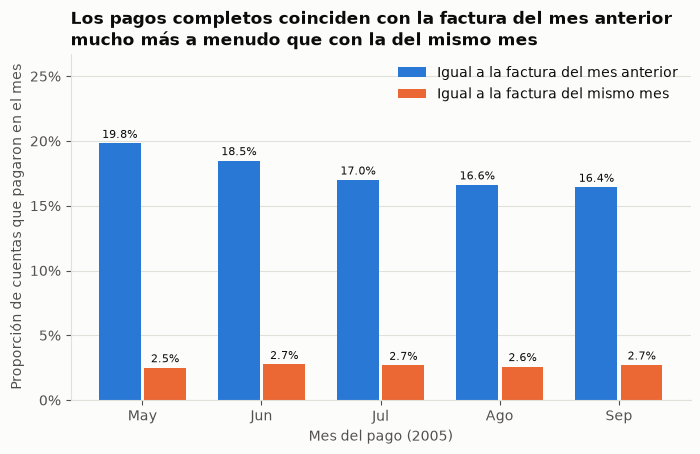

In [13]:
ordered = timing.sort_values("month", ascending=False)  # calendar order: May -> September
positions = range(len(ordered))
width = 0.38
series = [
    ("share_equals_previous_bill", "Igual a la factura del mes anterior", plotting.BLUE),
    ("share_equals_same_month_bill", "Igual a la factura del mismo mes", plotting.ORANGE),
]

fig, ax = plt.subplots(figsize=(8, 4.5))
for (column, label, colour), offset in zip(series, [-width / 2, width / 2], strict=True):
    x = [p + offset for p in positions]
    bars = ax.bar(x, ordered[column], width=width - 0.03, color=colour, label=label)
    ax.bar_label(bars, labels=[f"{v:.1%}" for v in ordered[column]], padding=2, fontsize=8)
ax.set_xticks(list(positions), ordered["calendar_month"])
ax.set_xlabel("Mes del pago (2005)")
ax.set_ylabel("Proporción de cuentas que pagaron en el mes")
ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right")
ax.set_ylim(0, ordered["share_equals_previous_bill"].max() * 1.35)
ax.set_title(
    "Los pagos completos coinciden con la factura del mes anterior\n"
    "mucho más a menudo que con la del mismo mes"
)
plotting.save_figure(fig, "eda_payment_timing")
plt.show()

El pago es igual al estado de cuenta anterior en el 16.4% a 19.8% de las cuentas que pagan, y al del
mismo mes en el 2.5% a 2.7%. La columna "pago = ambas facturas" muestra que casi todas las
coincidencias con el mismo mes son cuentas cuyos dos estados de cuenta tienen el mismo monto, así
que no son evidencia a favor de la lectura del mismo mes.

**Verificación 2: todas las cuentas.** La verificación 1 solo habla de los clientes que pagan
completo. Una segunda verificación usa todas las cuentas. Un estado de cuenta es el estado de cuenta
anterior, menos el pago, más las compras y cargos nuevos, así que las compras implícitas entre dos
estados de cuenta consecutivos y el pago entre ellos no deberían ser negativas. La tabla da la
proporción de cuentas con compras implícitas negativas bajo cada lectura.

In [14]:
purchases = quality.implied_purchases(raw)
purchases.insert(1, "calendar_month", purchases["month"].map(MONTH_LABELS))
purchase_shares = [c for c in purchases.columns if c.startswith("share_")]
show(purchases.set_index("month"), percent=purchase_shares)

,mes calendario,compras negativas si cancela la factura anterior,compras negativas si cancela la del mismo mes
mes,,,
2,Ago,0.4%,17.1%
3,Jul,0.4%,19.1%
4,Jun,0.4%,18.0%
5,May,0.4%,15.8%


Con la lectura "estado de cuenta anterior", alrededor del 0.4% de las cuentas tiene compras
implícitas negativas en cada mes (las devoluciones pueden explicar una proporción de ese tamaño).
Con la lectura "mismo mes" es del 15.8% al 19.1%. Las dos verificaciones coinciden.

**Decisión (ADR-009).** `PAY_AMTk` se trata como el pago del estado de cuenta `BILL_AMT{k+1}`. Los
ratios de pago se construirán como `PAY_AMTk / BILL_AMT{k+1}`, lo que da cinco meses utilizables (el
estado de cuenta de abril no tiene un estado de cuenta anterior en el archivo).

## 8. Aplicación de la recodificación

El único cambio que se hace a los datos es la recodificación fija de la sección 2. Es un mapeo
escrito que no depende de los datos, así que aplicarlo antes de la partición train/test no filtra
información.

In [15]:
data = clean.recode_undocumented_codes(raw)

unchanged = [c for c in raw.columns if c not in clean.RECODES]
assert raw[unchanged].equals(data[unchanged])
assert len(data) == len(raw)

print("Filas recodificadas:", quality.recoded_row_counts(raw))
for column in clean.RECODES:
    print(column)
    table = quality.code_counts(data, column, DOCUMENTED_CODES[column])
    show(table.set_index("value"), percent=["share"], whole=["count"])

Filas recodificadas: {'EDUCATION': 345, 'MARRIAGE': 54}
EDUCATION


,cuentas,proporción,documentado
valor,,,
1,"10,585",35.3%,True
2,"14,030",46.8%,True
3,"4,917",16.4%,True
4,468,1.6%,True


MARRIAGE


,cuentas,proporción,documentado
valor,,,
1,"13,659",45.5%,True
2,"15,964",53.2%,True
3,377,1.3%,True


## 9. Columnas disponibles al momento de predecir

El modelo está pensado para puntuarse a fines de septiembre de 2005 y predecir el default de octubre
de 2005. La tabla lista cada grupo de columnas, el período que describe y cómo se usa.

In [16]:
groups = {
    "Límite y datos demográficos": ["LIMIT_BAL", "AGE", "EDUCATION"],
    "Estado de pago": PAY_COLS,
    "Montos facturados": BILL_COLS,
    "Montos pagados": PAYAMT_COLS,
    "Atributos sensibles": SENSITIVE_COLS,
    "Target": [TARGET],
}
period = {
    "Límite y datos demográficos": "sin fecha en el archivo",
    "Estado de pago": "abr-sep 2005",
    "Montos facturados": "abr-sep 2005",
    "Montos pagados": "abr-sep 2005",
    "Atributos sensibles": "sin fecha en el archivo",
    "Target": "oct 2005",
}
rows = []
for group, group_columns in groups.items():
    is_candidate = all(c in CANDIDATE_FEATURE_COLS for c in group_columns)
    use = "variable candidata" if is_candidate else "solo auditoría de equidad (ADR-002)"
    rows.append(
        {
            "grupo": group,
            "columnas": f"{group_columns[0]} ... {group_columns[-1]}",
            "n columnas": len(group_columns),
            "período": period[group],
            "uso": "resultado" if group == "Target" else use,
        }
    )
print(f"{len(CANDIDATE_FEATURE_COLS)} columnas candidatas a variable")
display(pd.DataFrame(rows).set_index("grupo"))

21 columnas candidatas a variable


,columnas,n columnas,período,uso
grupo,,,,
Límite y datos demográficos,LIMIT_BAL ... EDUCATION,3,sin fecha en el archivo,variable candidata
Estado de pago,PAY_1 ... PAY_6,6,abr-sep 2005,variable candidata
Montos facturados,BILL_AMT1 ... BILL_AMT6,6,abr-sep 2005,variable candidata
Montos pagados,PAY_AMT1 ... PAY_AMT6,6,abr-sep 2005,variable candidata
Atributos sensibles,SEX ... MARRIAGE,2,sin fecha en el archivo,solo auditoría de equidad (ADR-002)
Target,DEFAULT ... DEFAULT,1,oct 2005,resultado


Que todas las columnas candidatas se conocieran antes de octubre es un **SUPUESTO** que descansa en
la descripción del dataset. El archivo no trae fechas de registro. En ADR-009 quedan tres salvedades:

- `PAY_1` es la columna con más riesgo, por las razones de la sección 3.
- `LIMIT_BAL`, `AGE` y `EDUCATION` no tienen fecha. Un límite de crédito es algo que un banco ajusta
  en respuesta al comportamiento, así que podría reflejar una fecha posterior a septiembre.
- `AGE` y `EDUCATION` son candidatas solo a la espera de la justificación que exige ADR-002.

## Guardado de resultados

Toda cifra citada arriba, en `docs/DATA.md` y en `docs/DECISIONS.md` para esta fase sale de este
archivo.

In [17]:
metrics = quality.data_quality_report(raw)
path = save_metrics("data_quality", metrics, data_sha256)
print(f"Guardado en {path.relative_to(path.parents[2]).as_posix()}")

Guardado en reports/metrics/data_quality.json


## Resumen de decisiones

| Hallazgo | Decisión | Registrada en |
|---|---|---|
| Códigos no documentados de `EDUCATION` y `MARRIAGE` | Pasan a la categoría documentada "otros" | ADR-008 |
| Códigos −2 y 0 de `PAY_*` | Se conservan como categorías propias; su significado es un SUPUESTO | ADR-008 |
| Estado de septiembre registrado con otro criterio (código 1, códigos de atraso sin nada facturado) | Se conserva; se trata en la ingeniería de variables y en el análisis de cobranza | ADR-008 |
| Facturas negativas y sobre el límite | Se conservan; piso en cero solo dentro de las fórmulas que lo necesitan | ADR-008 |
| Cuentas inactivas | Se conservan en la población | ADR-008 |
| Filas idénticas | Se conservan todas; los gemelos a ambos lados de la partición se cuentan después | ADR-008 |
| Montos extremos | Se conservan; sin truncar | ADR-008 |
| Timing de pagos | `PAY_AMTk` cancela `BILL_AMT{k+1}` | ADR-009 |
| Columnas al momento de predecir | Las candidatas son anteriores al mes del resultado (SUPUESTO); `PAY_1` tendrá una verificación de fuga | ADR-009 |